In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn.objects as so

# Analisis inicial del flujo vehicular en la 'onda verde'

In [11]:
onda = pd.read_csv('volumen_vehicular_2024_detalle_semanal.csv')

In [12]:
cordoba = onda[onda['ubicacion_conteo'] == 'CORDOBA AV. 4471']

In [13]:
circuito = {
    'CORDOBA AV. 1147':    'oeste',
    'CORDOBA AV. 1431':    'oeste',
    'CORDOBA AV. 1749':    'oeste',
    'CORDOBA AV. 1980':    'oeste',

    'CORDOBA AV. 2149':    'oeste',
    'CORDOBA AV. 2523':    'oeste',
    'CORDOBA AV. 2801':    'oeste',

    'CORDOBA AV. 3143':    'oeste',
    'CORDOBA AV. 3329':    'oeste',
    'CORDOBA AV. 3647':    'oeste',

    'CORDOBA AV. 4471':    'oeste',
    'CORDOBA AV. 4570':    'oeste',
    
    


}
dias = ['VIE', 'LUN', 'MAR', 'MIE', 'JUE']

onda_8am = onda[
    (onda['ubicacion_conteo'].map(circuito) == onda['sentido_circulacion_conteo']) &
    (onda['franja_horaria_conteo'] == 8) &
    onda['dia_semana_conteo'].isin(dias)
].copy()

In [14]:
por_dia = (onda_8am.groupby(['ubicacion_conteo', 'fecha_conteo','sentido_circulacion_conteo','cuarto_hora_conteo'])['conteo_vehiculos'].sum())

In [15]:
prom_onda_8am = (por_dia.groupby(['ubicacion_conteo','sentido_circulacion_conteo', 'cuarto_hora_conteo']).mean().reset_index(name='vehiculos_promedio'))

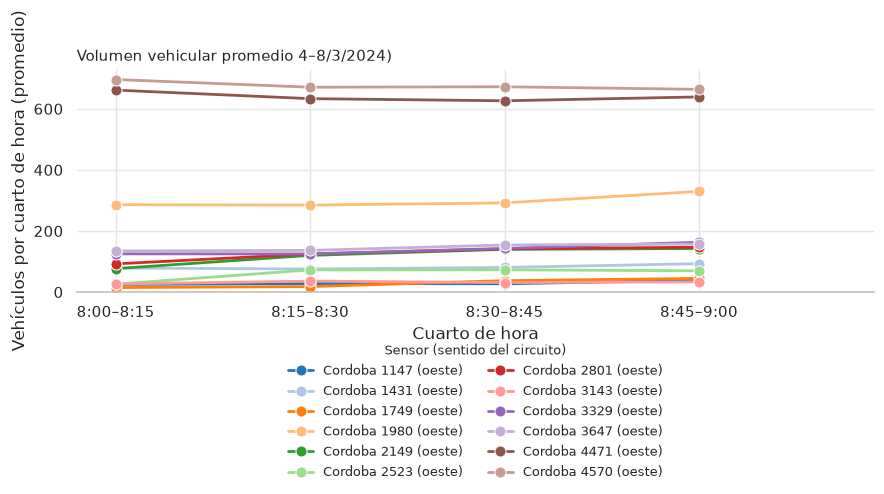

In [16]:
cuartos = {1: '8:00–8:15', 2: '8:15–8:30', 3: '8:30–8:45', 4: '8:45–9:00'}
prom_onda_8am['cuarto'] = prom_onda_8am['cuarto_hora_conteo'].map(cuartos)
prom_onda_8am['sensor'] = (prom_onda_8am['ubicacion_conteo'].str.replace(' AV.', '', regex=False).str.title() + ' (' + prom_onda_8am['sentido_circulacion_conteo'] + ')')

orden = ['Cordoba 1147 (oeste)', 'Cordoba 1431 (oeste)', 'Cordoba 1749 (oeste)', 'Cordoba 1980 (oeste)', 'Cordoba 2149 (oeste)','Cordoba 2523 (oeste)','Cordoba 2801 (oeste)', 'Cordoba 3143 (oeste)', 'Cordoba 3329 (oeste)', 'Cordoba 3647 (oeste)', 'Cordoba 4471 (oeste)', 'Cordoba 4570 (oeste)']

colores = dict(zip(orden, sns.color_palette('tab20', len(orden))))

sns.set_theme(style='whitegrid', rc={'grid.color': '#e5e5e5', 'axes.edgecolor': "#cac1c1"})
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=prom_onda_8am, x='cuarto', y='vehiculos_promedio', hue='sensor', hue_order=orden, palette=colores, marker='o', markersize=8, linewidth=2, sort=False, ax=ax)

for s in orden:
    y = prom_onda_8am.loc[(prom_onda_8am['cuarto_hora_conteo'] ==4), 'vehiculos_promedio'].iloc[0]

ax.set_title('Volumen vehicular promedio 4–8/3/2024)', loc='left', fontsize=11)
ax.set_xlabel('Cuarto de hora')
ax.set_ylabel('Vehículos por cuarto de hora (promedio)')
ax.set_ylim(0, None)
ax.set_xlim(-0.2, 3.9)
ax.legend(title='Sensor (sentido del circuito)', frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9, title_fontsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Simulaciones

In [17]:
semaforos_onda = pd.read_csv('semaforos_cordoba_oeste.csv')

In [18]:
#################################################################
############  Av. Córdoba (recta abierta, sentido oeste): datos y armado del modelo

# --- supuestos míos, cambialos si tenés los reales ---
T_CICLO = 90.0        # s, ciclo común de todos los semáforos
V_KMH   = 30.0        # km/h, velocidad de marcha
CUARTO  = 0           # 0 = 8:00-8:15, 1 = 8:15-8:30, 2 = 8:30-8:45, 3 = 8:45-9:00
QUITAR_ULTIMOS = 2    # cuántos semáforos del final se sacan (los 2 últimos son los de flujo ~600)

# --- semáforos (orden 1..35, sentido oeste): cruce y distancia [m] desde el inicio ---
cruces = ["Libertad", "Talcahuano", "Uruguay", "Paraná", "Montevideo", "Rodríguez Peña", "Callao Av.",
          "Riobamba", "Ayacucho", "Junín", "Uriburu José E. Pte.", "Pasteur", "Azcuénaga", "Larrea", "Paso",
          "Pueyrredón Av.", "Boulogne Sur Mer", "Ecuador", "Jean Jaures", "Anchorena T. de Dr.", "Agüero",
          "Gallo", "Sánchez de Bustamante", "Billinghurst", "Bravo Mario", "Bulnes", "Salguero Jerónimo",
          "Medrano Av.", "Acuña de Figueroa F.", "Gascón", "Palestina (ex Rawson)", "Pringles", "Lavalleja",
          "Alvarez Julián", "Araoz"]
pos = np.array([75.2, 206.0, 329.5, 455.7, 596.3, 768.5, 895.9, 1031.1, 1161.8, 1288.9,
                1435.4, 1539.6, 1645.9, 1780.8, 1848.5, 1922.2, 2023.3, 2105.0, 2197.3, 2340.6,
                2533.7, 2684.5, 2806.9, 2933.9, 3059.1, 3175.8, 3331.1, 3445.7, 3590.5, 3737.5,
                3888.5, 4032.5, 4116.2, 4238.4, 4361.4])

# --- sensores: dirección (número de calle) -> flujo [veh/15 min] en los 4 cuartos de hora ---
sensores = {1147: [25.0, 28.0, 27.2, 39.0],
            1431: [78.6, 75.6, 80.8, 93.0],
            1749: [14.8, 18.0, 37.4, 44.8],
            1980: [286.2, 284.8, 292.0, 329.6],
            2149: [76.8, 120.2, 140.0, 142.6],
            2523: [26.0, 72.6, 73.0, 69.6],
            2801: [92.4, 124.8, 141.4, 147.0],
            3143: [26.4, 36.0, 31.2, 33.6],
            3329: [125.2, 125.0, 143.0, 163.2],
            3647: [134.6, 136.6, 154.2, 157.2],
            4471: [661.333333, 633.333333, 626.333333, 639.0],
            4570: [696.0, 670.8, 672.2, 663.8]}

# posición de cada sensor sobre la avenida: el primero y el último van en el primer y último
# semáforo, y los del medio proporcionales al número de calle (esto se hace con los 35 semáforos)
direc = np.array(list(sensores.keys()))
pos_sensor = pos[0] + (direc - direc[0]) / (direc[-1] - direc[0]) * (pos[-1] - pos[0])
flujo_sensor = np.array([f[CUARTO] for f in sensores.values()])

# --- sacar los últimos semáforos y los sensores que quedan más allá ---
if QUITAR_ULTIMOS > 0:
    pos, cruces = pos[:-QUITAR_ULTIMOS], cruces[:-QUITAR_ULTIMOS]
dentro = pos_sensor <= pos[-1]
pos_sensor, flujo_sensor = pos_sensor[dentro], flujo_sensor[dentro]

n = len(pos)
dist = np.diff(pos)                                   # tramos: semáforo k -> k+1
print(f"{n} semáforos: de {cruces[0]} a {cruces[-1]} | {dentro.sum()} sensores usados")

# flujo de cada tramo: interpolado entre sensores, en el punto medio del tramo
# (después del último sensor queda constante)
medio = (pos[:-1] + pos[1:]) / 2
flujo_tramo = np.interp(medio, pos_sensor, flujo_sensor)

# --- adyacencia: recta de n nodos (no se cierra) ---
A = np.zeros((n, n))
for k in range(n - 1):
    A[k, k+1] = A[k+1, k] = 1

# --- Delta = 2*pi*L/(T*v) entre semáforos consecutivos ---
v = V_KMH / 3.6
Delta = np.zeros((n, n))
for k in range(n - 1):
    Delta[k, k+1] = Delta[k+1, k] = (2*np.pi*dist[k]/(T_CICLO*v)) % (2*np.pi)

# --- pesos K: solo en el sentido de circulación (k -> k+1, hacia el oeste) ---
K = np.zeros((n, n))
for k in range(n - 1):
    K[k, k+1] = flujo_tramo[k] / flujo_tramo.max()

33 semáforos: de Libertad a Lavalleja | 10 sensores usados


In [23]:
from scipy.integrate import solve_ivp      # resuelve ecuaciones diferenciales

# funciones de simulación (copiadas de Colab_investigathon)

def condiciones_iniciales_random(n, semilla=None):
    # Devuelve n fases al azar, uniformes entre 0 y 2*pi.
    rng = np.random.default_rng(semilla)    # generador de números aleatorios
    return rng.uniform(-np.pi, np.pi, n)


def ecuaciones(t, phi, A, K, Delta, omega=0.0):
    # dphi_i/dt = omega - dV/dphi_i
    #           = omega + (1/d) sum_{j vecino de i} [ (K_ji/2) sin(phi_j - phi_i - Delta_ji)
    #                                                + (K_ij/2) sin(phi_j - phi_i + Delta_ij) ]
    # (t no se usa, pero solve_ivp lo pide como primer argumento)
    n = len(phi)                            # cantidad de nodos
    d = A[0].sum()                          # grado
    dphi = np.full(n, omega)                # empieza con la frecuencia natural
    for i in range(n):                      # para cada nodo i
        for j in range(n):                  # mira todos los j
            if A[i, j] == 1:                # solo los vecinos aportan
                dphi[i] += (1 / d) * 0.5 * K[j, i] * np.sin(phi[j] - phi[i] - Delta[j, i])
                dphi[i] += (1 / d) * 0.5 * K[i, j] * np.sin(phi[j] - phi[i] + Delta[i, j])
    return dphi


def simular(phi0, A, K, Delta, T, omega=0.0):
    # Integra las ecuaciones desde t=0 hasta t=T partiendo de phi0.
    sol = solve_ivp(ecuaciones, (0, T), phi0, args=(A, K, Delta, omega),
                    rtol=1e-8, atol=1e-10)  # tolerancias chicas = más precisión
    return sol.t, sol.y                     # tiempos y fases (sol.y[i] es la fase del nodo i)


Corriendo 30 simulaciones para Av. Córdoba...


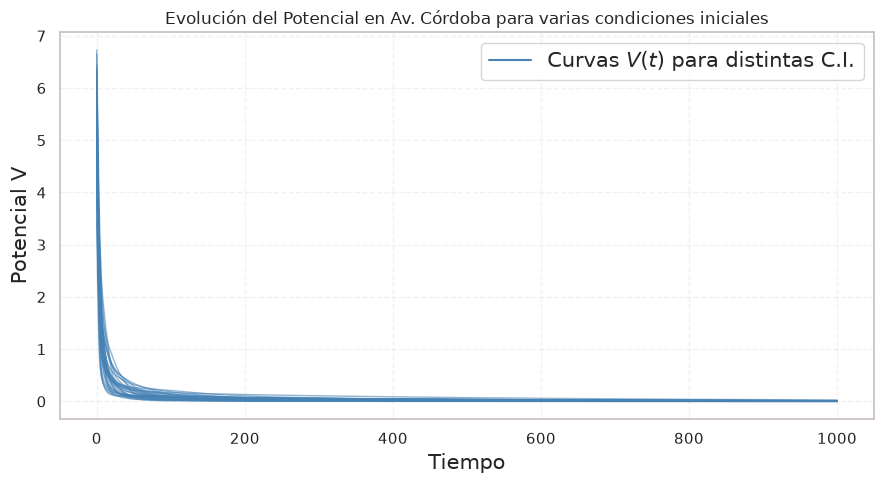

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# A. Avenida Córdoba: Múltiples Condiciones Iniciales (Escala Lineal y Optimizado)
# =============================================================================

T_SIM = 1000
N_CI_cordoba = 30  # Cantidad de condiciones iniciales a probar

plt.figure(figsize=(9, 5))
print(f"Corriendo {N_CI_cordoba} simulaciones para Av. Córdoba...")

# Función para calcular el potencial vectorizado en el tiempo
# Esto elimina el "for" de Python y calcula toda la trayectoria de un solo golpe
def potencial_vectorizado(phi_trayectoria, A, K, Delta):
    # phi_trayectoria tiene forma (n_nodos, n_tiempos)
    # Agregamos ejes para hacer broadcasting y obtener D de forma (n, n, n_tiempos)
    D = phi_trayectoria[None, :, :] - phi_trayectoria[:, None, :]

    # Adaptamos las matrices A, K y Delta agregándoles el eje de tiempo al final
    A_ext = A[:, :, None]
    K_ext = K.T[:, :, None]
    Delta_ext = Delta.T[:, :, None]

    d = A[0].sum()

    # Calculamos todo y sumamos sobre las filas y columnas de la red (ejes 0 y 1)
    # El resultado es un vector 1D con el potencial para cada instante de tiempo
    V_todos_los_tiempos = (A_ext * 0.5 * K_ext * (1 - np.cos(D - Delta_ext))).sum(axis=(0, 1)) / d
    return V_todos_los_tiempos

for b in range(N_CI_cordoba):
    # Generamos CI aleatorias
    phi0_cordoba = condiciones_iniciales_random(n, semilla=b)

    # Integramos usando tu función 'simular'
    t_c, phi_c = simular(phi0_cordoba, A, K, Delta, T_SIM)

    # Calculamos el potencial V(t) para TODA la trayectoria de una (ultra rápido)
    V_c = potencial_vectorizado(phi_c, A, K, Delta)

    # Ploteamos esta trayectoria (ya sin escala log)
    plt.plot(t_c, V_c, color="steelblue", lw=1.0, alpha=0.6)

# Truco para la leyenda
plt.plot([], [], color="steelblue", label=r"Curvas $V(t)$ para distintas C.I.")

# Ejes en escala lineal (se eliminaron symlog y log)
plt.xlabel("Tiempo", fontsize = 15)
plt.ylabel("Potencial V", fontsize = 15)
plt.title("Evolución del Potencial en Av. Córdoba para varias condiciones iniciales")
plt.legend(fontsize = 15)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

v = 20 km/h: corriendo 30 simulaciones...
v = 30 km/h: corriendo 30 simulaciones...
v = 40 km/h: corriendo 30 simulaciones...
v = 50 km/h: corriendo 30 simulaciones...
v = 60 km/h: corriendo 30 simulaciones...


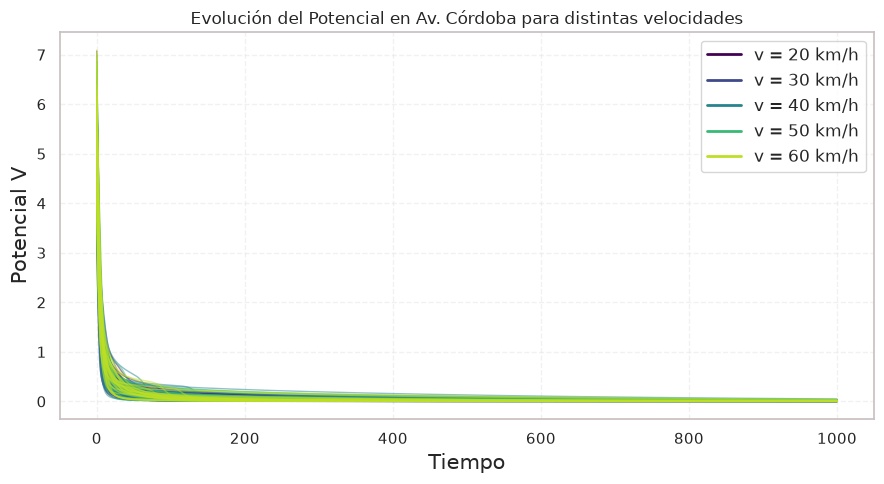

In [25]:
##### BARRIDO DE VELOCIDADES

# =============================================================================
# B. Barrido de velocidad: V(t) para varias C.I., todas las velocidades en un mismo gráfico
# =============================================================================

BARRER_V = True
velocidades_kmh = [20, 30, 40, 50, 60]   # km/h
colores = plt.cm.viridis(np.linspace(0, 0.9, len(velocidades_kmh)))   # gradiente, un color por v

if BARRER_V:
    plt.figure(figsize=(9, 5))

    for i in range(len(velocidades_kmh)):
        v_kmh = velocidades_kmh[i]
        # Delta depende de la velocidad; A y K no cambian
        v_ms = v_kmh / 3.6
        Delta_v = np.zeros((n, n))
        for k in range(n - 1):
            Delta_v[k, k+1] = Delta_v[k+1, k] = (2*np.pi*dist[k]/(T_CICLO*v_ms)) % (2*np.pi)

        print(f"v = {v_kmh} km/h: corriendo {N_CI_cordoba} simulaciones...")

        for b in range(N_CI_cordoba):
            phi0_cordoba = condiciones_iniciales_random(n, semilla=b)   # mismas semillas en cada v
            t_c, phi_c = simular(phi0_cordoba, A, K, Delta_v, T_SIM)
            V_c = potencial_vectorizado(phi_c, A, K, Delta_v)
            plt.plot(t_c, V_c, color=colores[i], lw=1.0, alpha=0.5)

        plt.plot([], [], color=colores[i], lw=2, label=f"v = {v_kmh} km/h")   # una entrada por velocidad

    plt.xlabel("Tiempo", fontsize=15)
    plt.ylabel("Potencial V", fontsize=15)
    plt.title("Evolución del Potencial en Av. Córdoba para distintas velocidades")
    plt.legend(fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()